<a href="https://colab.research.google.com/github/kdrhanegrilmez/mL-Notebooks/blob/main/EksikveAyk%C4%B1r%C4%B1Degerler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import zscore
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler


# Örnek DataFrame
data = {'A': [1, 2, np.nan, 4, 5, 500],
        'B': [6, np.nan, 8, 9, 10, 11],
        'C': ['X', 'Y', 'Z', 'X', 'Y', 'Z']}
df = pd.DataFrame(data)

print("Orijinal DataFrame:")
display(df)


# --- NaN (eksik) değerli satırları sil ---
df_temiz = df.dropna()

print("\nNaN değerli satırlar çıkarıldıktan sonra DataFrame:")
display(df_temiz)

Orijinal DataFrame:


,A,B,C
0,1.0,6.0,X
1,2.0,NaN,Y
2,NaN,8.0,Z
3,4.0,9.0,X
4,5.0,10.0,Y
5,500.0,11.0,Z



NaN değerli satırlar çıkarıldıktan sonra DataFrame:


,A,B,C
0,1.0,6.0,X
3,4.0,9.0,X
4,5.0,10.0,Y
5,500.0,11.0,Z


In [ ]:
# --- Aykırı değer tespiti ---
sayisal_kolonlar = df_temiz.select_dtypes(include=[np.number]).columns

# Z-skorlarını hesapla
z_skorlari = np.abs(zscore(df_temiz[sayisal_kolonlar]))

# DataFrame'e çevir
z_skorlari_df = pd.DataFrame(z_skorlari, columns=sayisal_kolonlar, index=df_temiz.index)
z_skorlari_df


# Aykırı değer maskesi
aykiri_maske = z_skorlari_df > 1.5

print("\nAykırı değer maskesi (True = aykırı değer):")
display(aykiri_maske)


Aykırı değer maskesi (True = aykırı değer):


,A,B
0,False,True
3,False,False
4,False,False
5,True,False


In [ ]:
# Aykırı değer içeren satırları göster
aykirilar = df_temiz[aykiri_maske.any(axis=1)]

print("\nEn az bir aykırı değer içeren satırlar:")
display(aykirilar)

# --- Aykırı değerleri çıkar ---
df_aykiri_olmadan = df_temiz[~aykiri_maske.any(axis=1)]

print("\nAykırı değer satırları çıkarıldıktan sonra DataFrame:")
display(df_aykiri_olmadan)


En az bir aykırı değer içeren satırlar:


,A,B,C
0,1.0,6.0,X
5,500.0,11.0,Z



Aykırı değer satırları çıkarıldıktan sonra DataFrame:


,A,B,C
3,4.0,9.0,X
4,5.0,10.0,Y


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Rastgele bir veri seti oluşturalım
np.random.seed(42)
data = {
    'Feature_1': np.random.normal(loc=100, scale=15, size=100),
    'Feature_2': np.random.normal(loc=50, scale=10, size=100),
    'Feature_3': np.random.randint(10, 100, size=100),
    'Category': np.random.choice(['A', 'B', 'C'], size=100)
}
df = pd.DataFrame(data)
df




# Eksik değerler ekleyelim
df.loc[np.random.choice(df.index, 10), 'Feature_1'] = np.nan
df.loc[np.random.choice(df.index, 5), 'Feature_2'] = np.nan
df.loc[np.random.choice(df.index, 3), 'Category'] = np.nan

# Aykırı değerler ekleyelim
df.loc[10, 'Feature_1'] = 250  # Outlier
df.loc[25, 'Feature_2'] = -50  # Outlier

print("Örnek Veri Setinin İlk 5 Satırı:")
display(df.head())
print("\nVeri Seti Bilgileri:")
display(df.info())


Örnek Veri Setinin İlk 5 Satırı:


,Feature_1,Feature_2,Feature_3,Category
0,107.450712,35.846293,11,B
1,97.926035,45.793547,99,B
2,109.715328,46.572855,26,A
3,122.845448,41.977227,42,C
4,96.487699,48.387143,18,A



Veri Seti Bilgileri:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature_1  90 non-null     float64
 1   Feature_2  95 non-null     float64
 2   Feature_3  100 non-null    int64  
 3   Category   97 non-null     object 
dtypes: float64(2), int64(1), object(1)
memory usage: 3.3+ KB


None

In [ ]:
df.to_excel('df_output2.xlsx', index=False)

In [ ]:
# Her sütundaki eksik değer sayısını bulma
missing_values = df.isnull().sum()
print("Her Sütundaki Eksik Değer Sayısı:")
display(missing_values)

# Her sütundaki eksik değerlerin yüzdesini bulma
missing_percentage = (df.isnull().sum() / len(df)) * 100
print("\nHer Sütundaki Eksik Değerlerin Yüzdesi:")
display(missing_percentage.sort_values(ascending=False))

Her Sütundaki Eksik Değer Sayısı:


,0
Feature_1,10
Feature_2,5
Feature_3,0
Category,3



Her Sütundaki Eksik Değerlerin Yüzdesi:


,0
Feature_1,10.0
Feature_2,5.0
Category,3.0
Feature_3,0.0


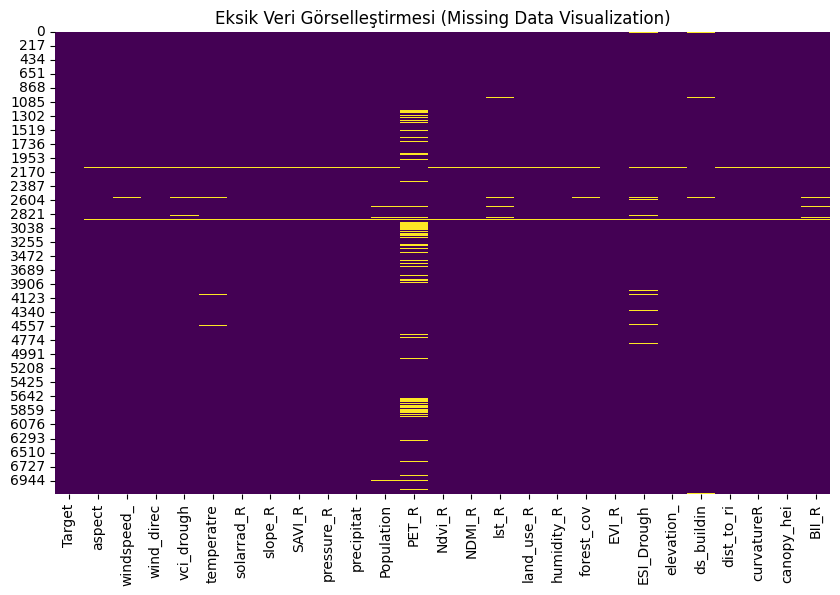

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Eksik Veri Görselleştirmesi (Missing Data Visualization)')
plt.show()

In [ ]:
# Eksik değer içeren satırları silme
df_dropped_rows = df.dropna()
print("Eksik değer içeren satırlar silindikten sonraki boyut:", df_dropped_rows.shape)

# Eksik değer içeren sütunları silme (dikkatli kullanılmalıdır)
df_dropped_cols = df.dropna(axis=1)
print("Eksik değer içeren sütunlar silindikten sonraki boyut:", df_dropped_cols.shape)

Eksik değer içeren satırlar silindikten sonraki boyut: (5930, 27)
Eksik değer içeren sütunlar silindikten sonraki boyut: (7144, 1)


In [ ]:
import os
print(os.listdir())

['.config', 'df_output2.xlsx', 'AllDataset_Raw.csv', 'sample_data']



Eksik veriler (sütun bazında):


,0
Target,0
aspect,29
windspeed_,47
wind_direc,30
vci_drough,75
temperatre,69
solarrad_R,36
slope_R,30
SAVI_R,32
pressure_R,30


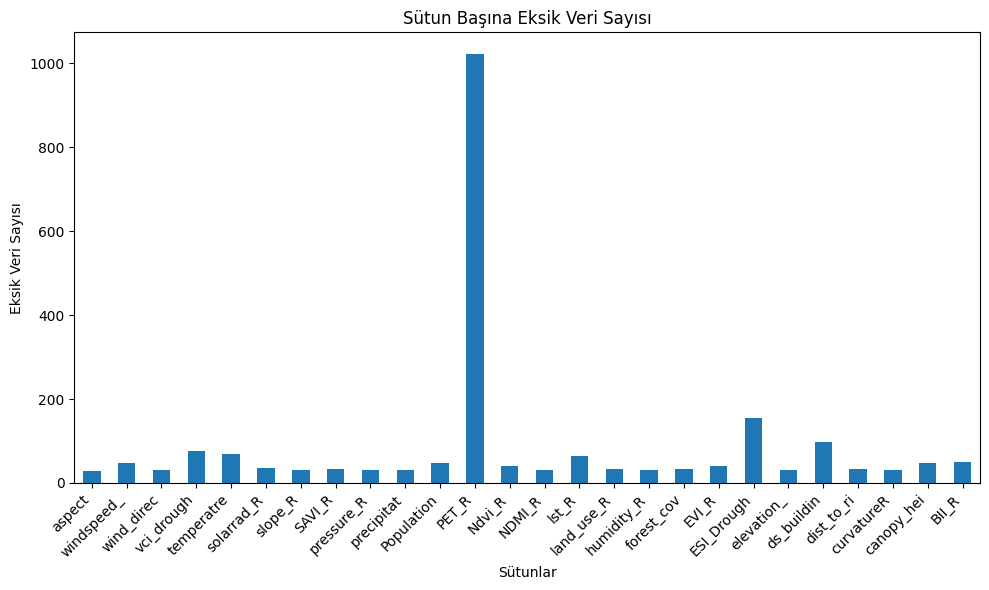

In [ ]:
# Google Drive'ı bağla
# from google.colab import drive
# drive.mount('/content/drive')

# Veri seti yolu
data_path = "/content/drive/My Drive/Projects/2025/IzmerWUI/"

# CSV dosyasını oku
# df = pd.read_csv(data_path + "AllDataset_Raw.csv")
df = pd.read_csv("AllDataset_Raw.csv")

# Hedef değişkeni tanımla (y)
y = df['Target']

# Girdi özelliklerini (X) tanımla, Target sütununu çıkar
X = df.drop(['Target'], axis=1)

# Veri setini görüntüle
df


# Eksik verileri kontrol etme
missing_values = df.isnull().sum()

print("\nEksik veriler (sütun bazında):")
display(missing_values)

# Eksik verileri görselleştirme
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
missing_values[missing_values > 0].plot(kind='bar')
plt.title('Sütun Başına Eksik Veri Sayısı')
plt.xlabel('Sütunlar')
plt.ylabel('Eksik Veri Sayısı')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Rastgele bir veri seti oluşturalım
np.random.seed(42)
data = {
    'Feature_1': np.random.normal(loc=100, scale=15, size=15),
    'Feature_2': np.random.normal(loc=50, scale=10, size=15),
    'Feature_3': np.random.randint(10, 100, size=15),
    'Category': np.random.choice(['A', 'B', 'C'], size=15)
}
df = pd.DataFrame(data)
df

# Eksik değerler ekleyelim
df.loc[np.random.choice(df.index, 5), 'Feature_1'] = np.nan
df.loc[np.random.choice(df.index, 3), 'Feature_2'] = np.nan
df.loc[np.random.choice(df.index, 2), 'Category'] = np.nan

# Aykırı değerler ekleyelim
df.loc[10, 'Feature_1'] = 250  # Outlier
df.loc[25, 'Feature_2'] = -50  # Outlier
df

,Feature_1,Feature_2,Feature_3,Category
0,107.450712,44.377125,93.0,B
1,NaN,39.871689,69.0,B
2,109.715328,53.142473,80.0,A
3,122.845448,40.919759,53.0,C
4,NaN,NaN,17.0,B
5,96.487946,64.656488,56.0,B
6,123.688192,47.742237,44.0,B
7,NaN,NaN,87.0,B
8,92.957884,35.752518,90.0,NaN
9,108.138401,44.556173,45.0,NaN


In [ ]:
# Sayısal sütunlardaki eksik değerleri medyan ile doldurma
df_filled = df.copy()
df_filled['Feature_1'].fillna(df_filled['Feature_1'].median(), inplace=True)
df_filled['Feature_2'].fillna(df_filled['Feature_2'].mean(), inplace=True)

# Kategorik sütunlardaki eksik değerleri mod (en sık tekrar eden değer) ile doldurma
df_filled['Category'].fillna(df_filled['Category'].mode()[0], inplace=True)
df_filled
# print("Eksik değerler doldurulduktan sonraki eksik değer sayısı:")
# display(df_filled.isnull().sum())

/tmp/ipykernel_5218/3305261970.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_filled['Feature_1'].fillna(df_filled['Feature_1'].median(), inplace=True)
/tmp/ipykernel_5218/3305261970.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method

,Feature_1,Feature_2,Feature_3,Category
0,107.450712,44.377125,93.0,B
1,107.794556,39.871689,69.0,B
2,109.715328,53.142473,80.0,A
3,122.845448,40.919759,53.0,C
4,107.794556,39.105257,17.0,B
5,96.487946,64.656488,56.0,B
6,123.688192,47.742237,44.0,B
7,107.794556,39.105257,87.0,B
8,92.957884,35.752518,90.0,B
9,108.138401,44.556173,45.0,B


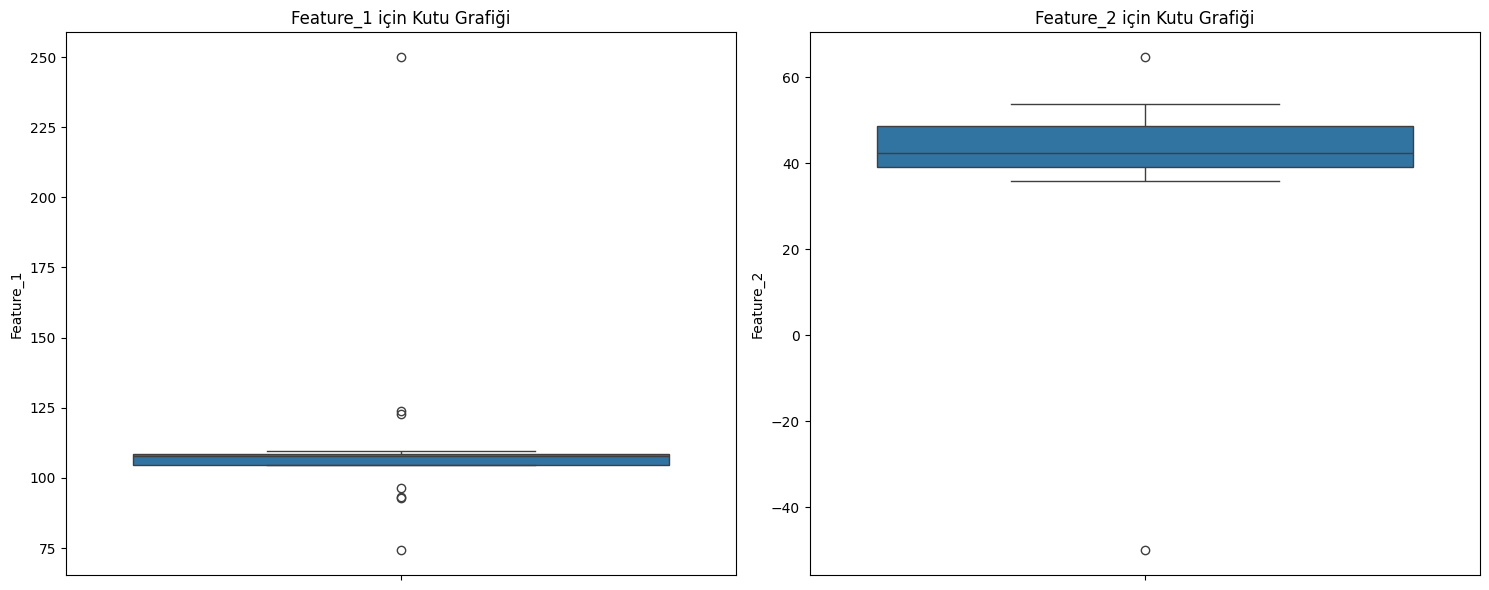

In [ ]:
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
sns.boxplot(y=df_filled['Feature_1'])
plt.title('Feature_1 için Kutu Grafiği')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_filled['Feature_2'])
plt.title('Feature_2 için Kutu Grafiği')
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import zscore

# Feature_1 için Z-skoru hesaplama
df_filled['Zscore_Feature_1'] = np.abs(zscore(df_filled['Feature_1']))
outliers_zscore_1 = df_filled[df_filled['Zscore_Feature_1'] > 3]
print("Feature_1 için Z-Skoru Metodu ile Tespit Edilen Aykırı Değerler (Z-Skoru > 3):")
display(outliers_zscore_1[['Feature_1', 'Zscore_Feature_1']])

# Feature_2 için Z-skoru hesaplama
df_filled['Zscore_Feature_2'] = np.abs(zscore(df_filled['Feature_2']))
outliers_zscore_2 = df_filled[df_filled['Zscore_Feature_2'] > 3]
print("\nFeature_2 için Z-Skoru Metodu ile Tespit Edilen Aykırı Değerler (Z-Skoru > 3):")
display(outliers_zscore_2[['Feature_2', 'Zscore_Feature_2']])

Feature_1 için Z-Skoru Metodu ile Tespit Edilen Aykırı Değerler (Z-Skoru > 3):


,Feature_1,Zscore_Feature_1
10,250.0,3.684576



Feature_2 için Z-Skoru Metodu ile Tespit Edilen Aykırı Değerler (Z-Skoru > 3):


,Feature_2,Zscore_Feature_2
25,-50.0,3.691962


In [ ]:
df_filled2 = df.copy()

# Sayısal sütunlarda eksik değerleri üst ve alt komşuların ortalamasıyla doldur
df_filled2['Feature_1'] = df_filled2['Feature_1'].interpolate(method='linear')
df_filled2

,Feature_1,Feature_2,Feature_3,Category
0,107.450712,44.377125,93.0,B
1,108.583020,39.871689,69.0,B
2,109.715328,53.142473,80.0,A
3,122.845448,40.919759,53.0,C
4,109.666697,NaN,17.0,B
5,96.487946,64.656488,56.0,B
6,123.688192,47.742237,44.0,B
7,108.323038,NaN,87.0,B
8,92.957884,35.752518,90.0,NaN
9,108.138401,44.556173,45.0,NaN
